# Unfallatlas 2025: PCA before Hist Gradient Boosting

**Task (same as in `tiziano_ensembles.ipynb`):** regress the binary target `severe` (killed or seriously injured) to predict
the probability of a severe outcome; the loss is the Brier score.

**Question:** does compressing the features with **principal component analysis (PCA)** before hist gradient boosting
improve the model, or at least keep the score with fewer inputs?

PCA replaces the 65 model columns with uncorrelated linear combinations (principal components), ordered by how much of
the **feature variance** they explain. Two reasons to be sceptical for this model:

* **PCA ignores the target.** The directions with the most variance in the features need not be the ones that predict severity.
* **Trees split on one column at a time.** A rule like "motorcycle involved" is one split on the original column. After PCA
  the motorcycle flag is spread across many components, and the trees have to rebuild the rule from several of them.

We test three set-ups, all with the tuned hist gradient boosting from `tiziano_ensembles.ipynb` and identical hyperparameters:

| set-up | inputs to the model |
| --- | --- |
| no PCA | the 65 preprocessed columns (reference) |
| PCA *k* | only the first *k* principal components, *k* = 5 … 65 (65 = pure rotation, no information lost) |
| original + PCA | the 65 columns **plus** the first 10 components as extra features |

Fitted on **train**, compared on **validation**; the test split stays untouched.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import KFold
from sklearn.pipeline import FeatureUnion, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder

RANDOM_STATE = 42

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                      "grid.color": "#e6e5e1", "axes.edgecolor": "#b5b4ad"})
COLORS = {"no PCA": "#2a78d6", "PCA": "#eb6834", "original + PCA": "#1baf7a"}
REFERENCE = "#8a8983"

## 1. Load the splits

Same loader and features as in `tiziano_ensembles.ipynb`.

In [2]:
TARGET = "severe"


def load_split(name):
    df = pd.read_csv(
        f"data/splits/{name}.csv.gz",
        dtype={"accident_id": str, "ags": str},
        parse_dates=["date"],
    )
    df["is_weekend"] = df["weekday"].isin(["Saturday", "Sunday"]).astype(int)
    df["log_density"] = np.log1p(df["population_per_km2"])
    return df


train = load_split("train")
val = load_split("val")

CATEGORICAL = ["state_name", "light", "road_condition", "weekday"]
BINARY = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle",
          "vulnerable", "single_type", "vulnerable_vs_vehicle", "is_weekend"]
NUMERIC = ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types",
           "longitude", "latitude", "log_density"]
HIGH_CARDINALITY = ["district"]
FEATURES = CATEGORICAL + BINARY + NUMERIC + HIGH_CARDINALITY

X_train, X_val = train[FEATURES], val[FEATURES]
y_train, y_val = train[TARGET], val[TARGET]
base_rate = y_train.mean()
print(f"train: {len(train):,} rows | val: {len(val):,} rows | base rate (train): {base_rate:.2%}")

train: 191,104 rows | val: 40,951 rows | base rate (train): 15.72%


## 2. Preprocessing for PCA

PCA needs numbers on a comparable scale, otherwise the column with the largest spread dominates the first component
(longitude in degrees would outweigh a 0/1 flag). So after encoding, every column is **standardised** (mean 0, standard deviation 1).

The full pipeline is `encode → standardise → PCA → hist gradient boosting`. Every step is fitted on train only. PCA is
unsupervised, but its directions still come from the training rows, so it belongs inside the pipeline.

In [3]:
def make_encoder():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("bin", "passthrough", BINARY),
        ("num", SimpleImputer(strategy="median"), NUMERIC),
        ("te", TargetEncoder(target_type="continuous",
                             cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)), HIGH_CARDINALITY),
    ], verbose_feature_names_out=False)


encoder = make_pipeline(make_encoder(), StandardScaler())
# fit_transform, not fit + transform: only then are the training rows target-encoded out-of-fold
Z_train = encoder.fit_transform(X_train, y_train)
feature_names = encoder[0].get_feature_names_out()
N_ALL = Z_train.shape[1]  # number of model columns = maximum number of principal components
print(f"{len(FEATURES)} raw features → {Z_train.shape[1]} standardised model columns")

23 raw features → 48 standardised model columns


## 3. Explore the principal components

### 3.1 Explained variance

How many components are needed to keep most of the information in the features?

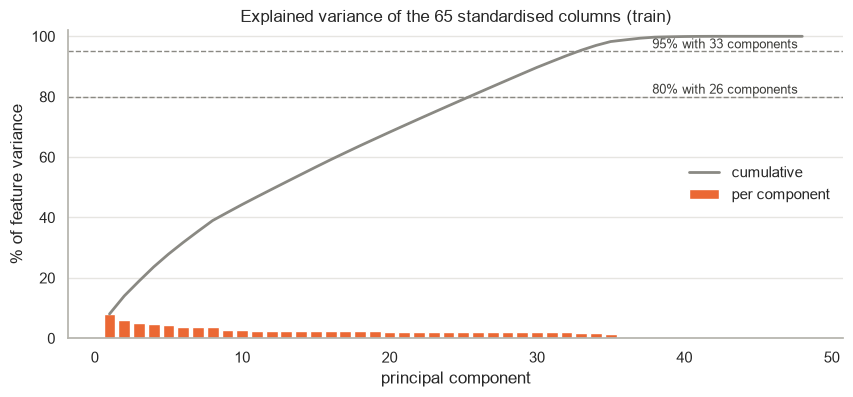

,components needed
share of variance,
0.50,13
0.80,26
0.90,31
0.95,33
0.99,37


In [4]:
pca_full = PCA(random_state=RANDOM_STATE).fit(Z_train)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_for = {share: int(np.searchsorted(cumulative, share) + 1) for share in [0.5, 0.8, 0.9, 0.95, 0.99]}

fig, ax = plt.subplots(figsize=(10, 4))
components = np.arange(1, len(cumulative) + 1)
ax.bar(components, pca_full.explained_variance_ratio_ * 100, color=COLORS["PCA"], width=0.8, label="per component")
ax.plot(components, cumulative * 100, color=REFERENCE, lw=2, label="cumulative")
for share in [0.8, 0.95]:
    ax.axhline(share * 100, color=REFERENCE, ls="--", lw=1)
    ax.text(len(components), share * 100, f"{share:.0%} with {n_for[share]} components ", ha="right", va="bottom",
            fontsize=9, color="#3d3d3a")
ax.set(xlabel="principal component", ylabel="% of feature variance", ylim=(0, 102),
       title=f"Explained variance of the {N_ALL} standardised columns (train)")
ax.legend(frameon=False, loc="center right")
ax.grid(axis="x", visible=False)
plt.show()
pd.Series(n_for, name="components needed").rename_axis("share of variance").to_frame()

The variance is spread out: no small set of components carries most of it. This is typical for data made of many one-hot and
0/1 columns that are only weakly correlated. PCA compresses well when columns are strongly correlated, and here they mostly are not.

### 3.2 What the first components mean

Loadings = the weight of each original column in a component. The largest absolute loadings name the component.

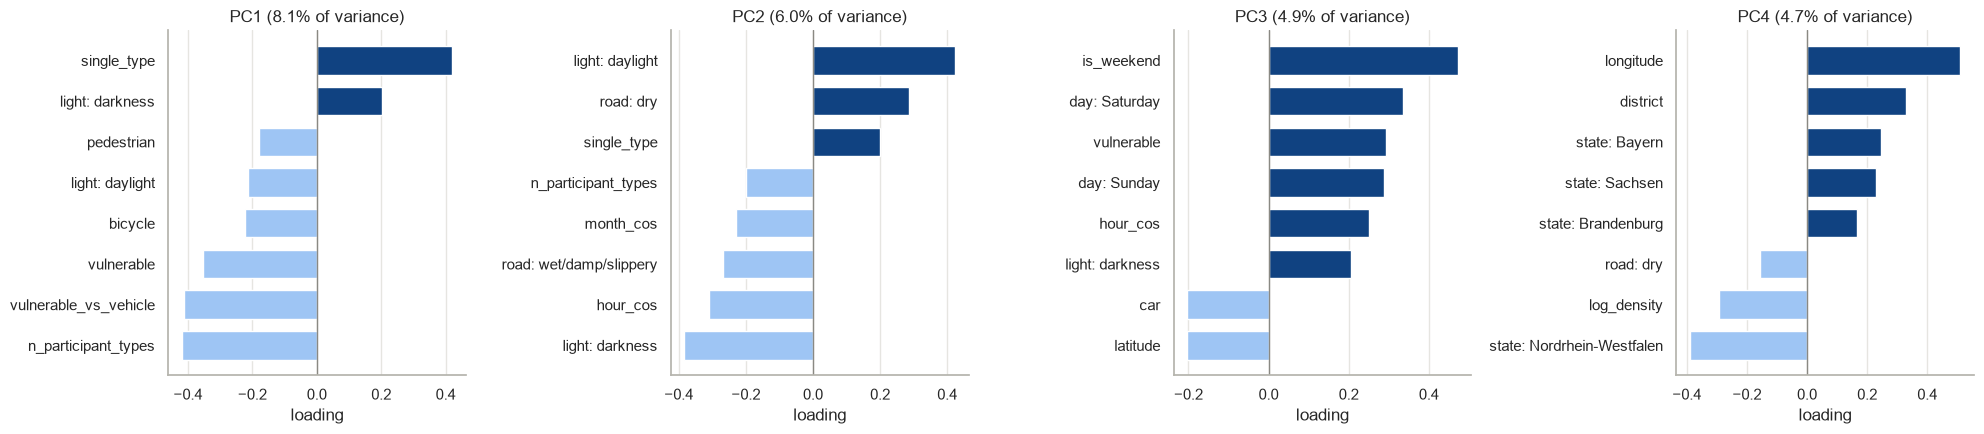

In [5]:
N_SHOW = 4
SHORT = {"state_name_": "state: ", "light_": "light: ",
         "road_condition_": "road: ", "weekday_": "day: ", "Collision with another vehicle ": "", "Collision ": "",
         "Accident caused by ": "", "Accident ": ""}


def short_name(name):
    for long, short in SHORT.items():
        name = name.replace(long, short)
    return name[:45]


loadings = pd.DataFrame(pca_full.components_[:N_SHOW].T, index=[short_name(n) for n in feature_names],
                        columns=[f"PC{i + 1}" for i in range(N_SHOW)])

fig, axes = plt.subplots(1, N_SHOW, figsize=(20, 4.5))
for ax, pc in zip(axes, loadings.columns):
    top = loadings[pc].reindex(loadings[pc].abs().nlargest(8).index).sort_values()
    ax.barh(top.index, top.values,
            color=np.where(top > 0, "#104281", "#9ec5f4"), height=0.7)
    ax.axvline(0, color=REFERENCE, lw=1)
    share = pca_full.explained_variance_ratio_[int(pc[2:]) - 1]
    ax.set(title=f"{pc} ({share:.1%} of variance)", xlabel="loading")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 3.3 Do the first two components separate severe accidents?

Training accidents projected onto PC1 and PC2. Each hexagon is coloured by the **share of severe accidents** in it.
If PCA found the "risk direction", the colour would change smoothly along one axis.

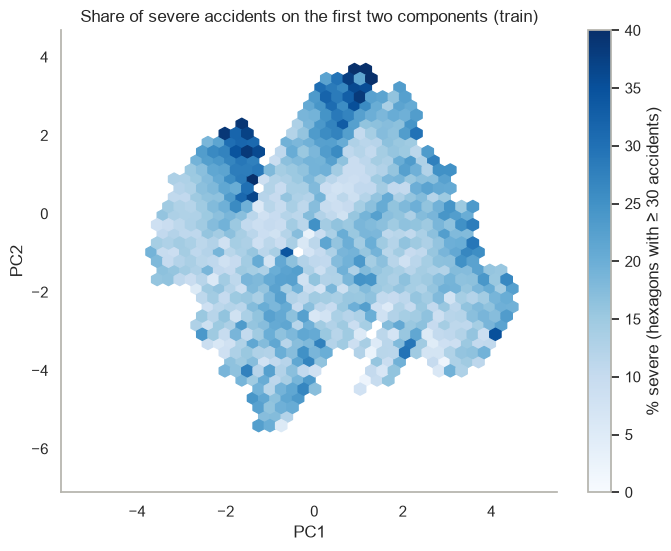

components most correlated with the target:


,8,3,4,31,6,10,35,2
|correlation|,0.095,0.088,0.076,0.059,0.053,0.05,0.048,0.042


In [6]:
P_train = pca_full.transform(Z_train)[:, :2]
fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(P_train[:, 0], P_train[:, 1], C=y_train.to_numpy() * 100, reduce_C_function=np.mean,
               gridsize=40, mincnt=30, cmap="Blues", vmin=0, vmax=40)
fig.colorbar(hb, ax=ax, label="% severe (hexagons with ≥ 30 accidents)")
ax.set(xlabel="PC1", ylabel="PC2", title="Share of severe accidents on the first two components (train)")
ax.grid(visible=False)
plt.show()

corr = pd.Series([np.corrcoef(pca_full.transform(Z_train)[:, i], y_train)[0, 1] for i in range(len(cumulative))],
                 index=components, name="correlation with target")
print("components most correlated with the target:")
corr.abs().nlargest(8).round(3).to_frame("|correlation|").T

## 4. Hist gradient boosting on principal components

Same tuned hyperparameters as in `tiziano_ensembles.ipynb` for every set-up. Early stopping holds out a random 10 % of train,
so each set-up is trained with **3 seeds**; we report the mean and spread.

In [7]:
# tuned in tiziano_ensembles.ipynb (randomised search, 3-fold CV on train)
HGB_PARAMS = dict(learning_rate=0.0455, max_leaf_nodes=48, min_samples_leaf=176, l2_regularization=2.065,
                  max_features=0.5, max_iter=2000, early_stopping=True, n_iter_no_change=30)
SEEDS = range(3)
N_EXTRA_PCS = 10


def make_model(setup, k=None, seed=0):
    steps = [make_encoder(), StandardScaler()]
    if setup == "PCA":
        steps.append(PCA(n_components=k, random_state=RANDOM_STATE))
    elif setup == "original + PCA":
        steps.append(FeatureUnion([
            ("original", FunctionTransformer()),
            ("pca", PCA(n_components=N_EXTRA_PCS, random_state=RANDOM_STATE)),
        ]))
    return make_pipeline(*steps, HistGradientBoostingRegressor(random_state=seed, **HGB_PARAMS))


brier_constant = brier_score_loss(y_val, np.full(len(y_val), base_rate))


def scores(p):
    p = np.clip(p, 0, 1)
    brier = brier_score_loss(y_val, p)
    return {"Brier": brier, "Brier skill": 1 - brier / brier_constant,
            "ROC-AUC": roc_auc_score(y_val, p), "PR-AUC": average_precision_score(y_val, p)}


N_COMPONENTS = [k for k in [5, 10, 20, 30, 40, 50] if k < N_ALL] + [N_ALL]
CONFIGS = [("no PCA", None)] + [("PCA", k) for k in N_COMPONENTS] + [("original + PCA", N_EXTRA_PCS)]

rows, predictions = [], {}
for setup, k in CONFIGS:
    preds = []
    for seed in SEEDS:
        model = make_model(setup, k, seed).fit(X_train, y_train)
        preds.append(model.predict(X_val))
        rows.append({"setup": setup, "components": k, "seed": seed,
                     "trees": model[-1].n_iter_, **scores(preds[-1])})
    predictions[(setup, k)] = np.mean(preds, axis=0)

per_seed = pd.DataFrame(rows)
summary = (per_seed.groupby(["setup", "components"], sort=False, dropna=False)
           [["Brier skill", "ROC-AUC", "PR-AUC", "trees"]].agg(["mean", "std"]))
summary.round(4)

ValueError: n_components=50 must be between 0 and min(n_samples, n_features)=48 with svd_solver='covariance_eigh'

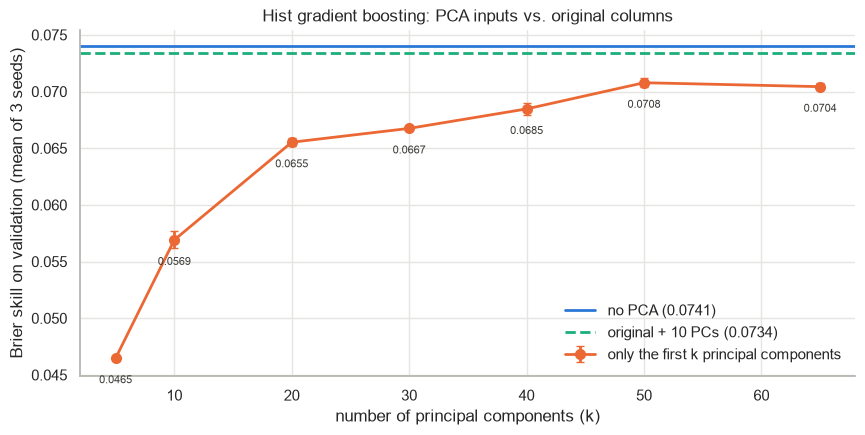

In [ ]:
means = per_seed.groupby(["setup", "components"], dropna=False)["Brier skill"].agg(["mean", "std"])
pca_curve = means.loc["PCA"]
no_pca = means.loc["no PCA"].iloc[0]
with_extra = means.loc["original + PCA"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(pca_curve.index, pca_curve["mean"], yerr=pca_curve["std"], color=COLORS["PCA"], lw=2,
            marker="o", ms=7, capsize=3, label="only the first k principal components")
ax.axhline(no_pca["mean"], color=COLORS["no PCA"], lw=2, label=f"no PCA ({no_pca['mean']:.4f})")
ax.axhline(with_extra["mean"], color=COLORS["original + PCA"], lw=2, ls="--",
           label=f"original + {N_EXTRA_PCS} PCs ({with_extra['mean']:.4f})")
for k, row in pca_curve.iterrows():
    ax.text(k, row["mean"] - 0.0015, f"{row['mean']:.4f}", ha="center", va="top", fontsize=8, color="#3d3d3a")
ax.set(xlabel="number of principal components (k)", ylabel="Brier skill on validation (mean of 3 seeds)",
       title="Hist gradient boosting: PCA inputs vs. original columns")
ax.legend(frameon=False, loc="lower right")
plt.show()

### Is the difference real?

Paired bootstrap on validation (1,000 resamples): difference in Brier skill to the no-PCA model, using the seed-averaged
predictions. If the 95 % interval excludes 0, the difference is not just noise.

In [ ]:
def paired_bootstrap(p_new, p_ref, n=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y = y_val.to_numpy()
    p_new, p_ref = np.clip(p_new, 0, 1), np.clip(p_ref, 0, 1)
    diffs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        constant = np.mean((y[i] - base_rate) ** 2)
        diffs.append((np.mean((y[i] - p_ref[i]) ** 2) - np.mean((y[i] - p_new[i]) ** 2)) / constant)
    return np.mean(diffs), *np.percentile(diffs, [2.5, 97.5])


reference = predictions[("no PCA", None)]
comparison = pd.DataFrame([
    {"setup": setup, "components": k, **scores(predictions[(setup, k)]),
     **dict(zip(["Δ Brier skill", "95 % CI low", "95 % CI high"], paired_bootstrap(predictions[(setup, k)], reference)))}
    for setup, k in CONFIGS if setup != "no PCA"
])
comparison.round(4)

,setup,components,Brier,Brier skill,ROC-AUC,PR-AUC,Δ Brier skill,95 % CI low,95 % CI high
0,PCA,5,0.1262,0.0470,0.6626,0.2675,-0.0277,-0.0315,-0.0242
1,PCA,10,0.1248,0.0578,0.6814,0.2822,-0.0169,-0.0198,-0.0141
2,PCA,20,0.1237,0.0665,0.6935,0.2943,-0.0083,-0.0104,-0.0063
3,PCA,30,0.1235,0.0677,0.6958,0.2955,-0.0071,-0.0091,-0.0049
4,PCA,40,0.1232,0.0696,0.6981,0.2979,-0.0052,-0.0071,-0.0033
5,PCA,50,0.1230,0.0718,0.7020,0.3002,-0.0030,-0.0047,-0.0012
6,PCA,65,0.1230,0.0716,0.7017,0.2998,-0.0032,-0.0049,-0.0016
7,original + PCA,10,0.1226,0.0743,0.7041,0.3049,-0.0005,-0.0014,0.0004


## 5. Which models suit PCA?

Hist gradient boosting suffers from PCA because trees are **not rotation-invariant**: they split along the axes.
Models that only see distances or dot products are rotation-invariant, so for them PCA with all components changes nothing. Dropping
components can then only help in two ways: as **regularisation** (fewer directions to fit) or by removing **noise
dimensions** that blur distances. We try four such models:

| model | what PCA does for it |
| --- | --- |
| **Linear regression on components** (principal component regression, PCR) | with all 65 components identical to linear regression; fewer components = a hard form of regularisation (ridge regression is the soft form) |
| **Partial least squares (PLS)** | the supervised cousin of PCR: components are chosen to covary with the **target**, not just to explain feature variance |
| **k-nearest neighbours (kNN)** | predicts the share of severe accidents among the most similar training accidents; fewer dimensions → cleaner distances, faster search |
| **RBF kernel ridge** (Nyström approximation) | a non-linear model built on distances; Nyström approximates the kernel with 1,500 random landmarks so it scales to 190k rows |

These models train in seconds (except the kernel model), so one seed is enough.

In [ ]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

# encode + standardise once (fitted on train); PCA with all components, so the first k columns are "PCA k"
Z_val = encoder.transform(X_val)
P_train, P_val = pca_full.transform(Z_train), pca_full.transform(Z_val)


def first(k, P):
    return P[:, :k]


linear_rows = []
for k in N_COMPONENTS:
    p = LinearRegression().fit(first(k, P_train), y_train).predict(first(k, P_val))
    linear_rows.append({"model": "PCR", "components": k, **scores(p)})
for k in [1, 2, 3, 5, 10, 20]:
    p = PLSRegression(n_components=k, scale=False).fit(Z_train, y_train).predict(Z_val).ravel()
    linear_rows.append({"model": "PLS", "components": k, **scores(p)})

p_linear = LinearRegression().fit(Z_train, y_train).predict(Z_val)
linear_reference = scores(p_linear)
print(f"linear regression on the standardised columns (no PCA): Brier skill {linear_reference['Brier skill']:.4f}")
pd.DataFrame(linear_rows).set_index(["model", "components"]).round(4)

linear regression on the standardised columns (no PCA): Brier skill 0.0590


Brier  Brier skill  ROC-AUC  PR-AUC
model components                                      
PCR   5           0.1279       0.0342   0.6432  0.2453
      10          0.1265       0.0450   0.6639  0.2639
      20          0.1259       0.0496   0.6706  0.2699
      30          0.1258       0.0500   0.6715  0.2700
      40          0.1251       0.0556   0.6809  0.2773
      50          0.1247       0.0589   0.6863  0.2811
      65          0.1246       0.0590   0.6865  0.2813
PLS   1           0.1255       0.0526   0.6769  0.2723
      2           0.1250       0.0563   0.6818  0.2791
      3           0.1248       0.0582   0.6844  0.2808
      5           0.1247       0.0589   0.6862  0.2814
      10          0.1246       0.0591   0.6865  0.2816
      20          0.1246       0.0591   0.6865  0.2815

**PCR with all 65 components gives exactly the linear-regression score**: a rotation does not change a least-squares fit.
With fewer components it is only worse. With 190k rows and 65 columns linear regression does not overfit, so there
is nothing for this regularisation to fix. PLS reaches the full linear score with about 5 components, because it picks directions
that predict the target. But it cannot go beyond it: both are still linear models.

### 5.1 kNN and RBF kernel ridge

Both have a setting that must be tuned (the number of neighbours; the kernel width `gamma`). We tune it on a **20 % holdout of
train**, not on validation, separately for each number of components.

In [ ]:
fit_idx, hold_idx = train_test_split(np.arange(len(y_train)), test_size=0.2, random_state=RANDOM_STATE)
y_fit, y_hold = y_train.to_numpy()[fit_idx], y_train.to_numpy()[hold_idx]


def holdout_brier(model, k):
    model.fit(first(k, P_train)[fit_idx], y_fit)
    return brier_score_loss(y_hold, np.clip(model.predict(first(k, P_train)[hold_idx]), 0, 1))


def make_knn(n_neighbors):
    return KNeighborsRegressor(n_neighbors=n_neighbors, n_jobs=-1)


def make_kernel_ridge(gamma, n_landmarks=1500):
    return make_pipeline(Nystroem(gamma=gamma, n_components=n_landmarks, random_state=RANDOM_STATE),
                         RidgeCV(alphas=np.logspace(-2, 3, 6)))


KNN_COMPONENTS = [k for k in [5, 10, 20, 40] if k < N_ALL] + [N_ALL]
KERNEL_COMPONENTS = [k for k in [10, 20, 40] if k < N_ALL] + [N_ALL]
tuned = []
for k in KNN_COMPONENTS:
    best = min([100, 200, 400], key=lambda n: holdout_brier(make_knn(n), k))
    tuned.append({"model": "kNN", "components": k, "setting": f"n_neighbors={best}", "value": best})
for k in KERNEL_COMPONENTS:
    # gamma scaled by 1/k: with standardised inputs, squared distances grow with the number of dimensions
    best = min([0.01, 0.03, 0.1, 0.3], key=lambda g: holdout_brier(make_kernel_ridge(g / k, n_landmarks=500), k)) / k
    tuned.append({"model": "RBF kernel ridge", "components": k, "setting": f"gamma={best:.4f}", "value": best})
tuned = pd.DataFrame(tuned)
tuned[["model", "components", "setting"]]

,model,components,setting
0,kNN,5,n_neighbors=200
1,kNN,10,n_neighbors=200
2,kNN,20,n_neighbors=200
3,kNN,40,n_neighbors=200
4,kNN,65,n_neighbors=200
5,RBF kernel ridge,10,gamma=0.0100
6,RBF kernel ridge,20,gamma=0.0015
7,RBF kernel ridge,40,gamma=0.0003
8,RBF kernel ridge,65,gamma=0.0002


In [ ]:
nonlinear_rows = []
for row in tuned.itertuples():
    k = row.components
    model = make_knn(int(row.value)) if row.model == "kNN" else make_kernel_ridge(row.value)
    p = model.fit(first(k, P_train), y_train).predict(first(k, P_val))
    nonlinear_rows.append({"model": row.model, "components": k, "setting": row.setting, **scores(p)})

all_rows = pd.concat([pd.DataFrame(linear_rows), pd.DataFrame(nonlinear_rows)], ignore_index=True)
all_rows.set_index(["model", "components"]).round(4)

Brier  Brier skill  ROC-AUC  PR-AUC  \
model            components                                         
PCR              5           0.1279       0.0342   0.6432  0.2453   
                 10          0.1265       0.0450   0.6639  0.2639   
                 20          0.1259       0.0496   0.6706  0.2699   
                 30          0.1258       0.0500   0.6715  0.2700   
                 40          0.1251       0.0556   0.6809  0.2773   
                 50          0.1247       0.0589   0.6863  0.2811   
                 65          0.1246       0.0590   0.6865  0.2813   
PLS              1           0.1255       0.0526   0.6769  0.2723   
                 2           0.1250       0.0563   0.6818  0.2791   
                 3           0.1248       0.0582   0.6844  0.2808   
                 5           0.1247       0.0589   0.6862  0.2814   
                 10          0.1246       0.0591   0.6865  0.2816   
                 20          0.1246       0.0591   0.6865  0.2815   
kNN              5           0.1262       0.0473   0.6633  0.2656   
                 10          0.1251       0.0553   0.6773  0.2768   
                 20          0.1248       0.0576   0.6811  0.2818   
                 40          0.1250       0.0560   0.6809  0.2792   
                 65          0.1246       0.0595   0.6859  0.2836   
RBF kernel ridge 10          0.1246       0.0592   0.6830  0.2849   
                 20          0.1238       0.0656   0.6914  0.2947   
                 40          0.1233       0.0688   0.6971  0.2969   
                 65          0.1230       0.0714   0.7012  0.3001   

                                     setting  
model            components                   
PCR              5                       NaN  
                 10                      NaN  
                 20                      NaN  
                 30                      NaN  
                 40                      NaN  
                 50                      NaN  
                 65                      NaN  
PLS              1                       NaN  
                 2                       NaN  
                 3                       NaN  
                 5                       NaN  
                 10                      NaN  
                 20                      NaN  
kNN              5           n_neighbors=200  
                 10          n_neighbors=200  
                 20          n_neighbors=200  
                 40          n_neighbors=200  
                 65          n_neighbors=200  
RBF kernel ridge 10             gamma=0.0100  
                 20             gamma=0.0015  
                 40             gamma=0.0003  
                 65             gamma=0.0002

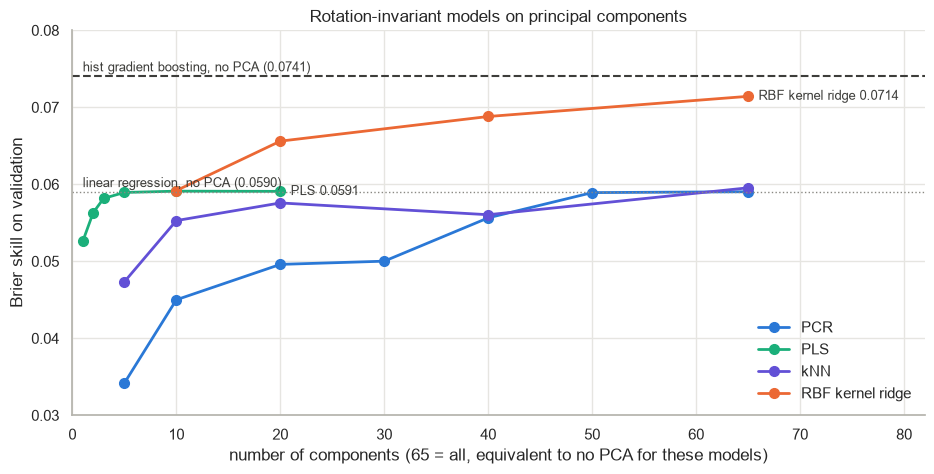

In [ ]:
MODEL_COLORS = {"PCR": "#2a78d6", "PLS": "#1baf7a", "kNN": "#6250d6", "RBF kernel ridge": "#eb6834"}
hgb_no_pca = means.loc["no PCA"].iloc[0]["mean"]

fig, ax = plt.subplots(figsize=(11, 5))
for name, color in MODEL_COLORS.items():
    curve = all_rows[all_rows["model"] == name].sort_values("components")
    ax.plot(curve["components"], curve["Brier skill"], color=color, lw=2, marker="o", ms=7, label=name)
    last = curve.iloc[-1]
    if name in ("kNN", "PCR"):  # end on the linear-regression line, where the reference label already sits
        continue
    ax.text(last["components"] + 1, last["Brier skill"], f"{name} {last['Brier skill']:.4f}",
            va="center", fontsize=9, color="#3d3d3a")
ax.axhline(hgb_no_pca, color="#3d3d3a", lw=1.5, ls="--")
ax.text(1, hgb_no_pca + 0.0006, f"hist gradient boosting, no PCA ({hgb_no_pca:.4f})", fontsize=9, color="#3d3d3a")
ax.axhline(linear_reference["Brier skill"], color=REFERENCE, lw=1, ls=":")
ax.text(1, linear_reference["Brier skill"] + 0.0006, f"linear regression, no PCA ({linear_reference['Brier skill']:.4f})",
        fontsize=9, color="#3d3d3a")
ax.set(xlabel=f"number of components ({N_ALL} = all, equivalent to no PCA for these models)", xlim=(0, N_ALL * 1.26),
       ylabel="Brier skill on validation", ylim=(0.03, 0.08),
       title="Rotation-invariant models on principal components")
ax.legend(frameon=False, loc="lower right")
plt.show()

## 6. Summary

**Hist gradient boosting after PCA** (§ 4; mean of 3 seeds, Δ from a paired bootstrap)

| set-up | Brier skill | Δ vs. no PCA (95 % CI) |
| --- | --- | --- |
| **no PCA** | **0.0741** | |
| PCA, 5 / 20 / 40 components | 0.0465 / 0.0655 / 0.0685 | −0.028 / −0.008 / −0.005, all significant |
| PCA, 65 components (pure rotation) | 0.0704 | −0.003 (−0.005 to −0.002) |
| original + 10 components | 0.0734 | −0.0005 (−0.0014 to +0.0004) |

**Models that suit PCA better** (§ 5; best number of components)

| model | best set-up | Brier skill |
| --- | --- | --- |
| Linear regression on components (PCR) | 65 components = plain linear regression | 0.0590 |
| Partial least squares (PLS) | 5–10 components | 0.0591 |
| kNN (200 neighbours) | 65 components = no PCA | 0.0595 |
| RBF kernel ridge | 65 components = no PCA | 0.0714 |
| *hist gradient boosting, no PCA (reference)* | | *0.0741* |

* **The features do not compress well.** PC1 explains only 7 % of the variance, and 33 components are needed for 80 %. One-hot and
  0/1 columns are only weakly correlated, so there is little redundancy for PCA to remove. The components most correlated with
  the target are PC5 and PC2, not PC1: PCA orders components by feature variance, not by how well they predict the target.
* **Hist gradient boosting gets worse with PCA in every set-up**, even with all 65 components, which loses no information. The loss
  comes from the rotation alone: trees split along one column at a time.
* **Linear regression is the textbook partner for PCA (PCR), but here PCA cannot help it.** With all components PCR *is* linear
  regression; with fewer components it only gets worse. PCR helps when there are many strongly correlated columns and few rows;
  here there are 190k rows and 65 weakly correlated columns, so linear regression does not overfit. PLS chooses its components with the target
  and reaches the full linear score with 5 components, but it is still a linear model and cannot beat it.
* **kNN and RBF kernel ridge are rotation-invariant, so PCA does not hurt them the way it hurts trees, but it does not help them
  either.** Both are best with all components, i.e. without dimensionality reduction. The kernel model is the best non-tree model
  (0.0714, clearly above linear regression, because it captures interactions) but still below hist gradient boosting, and it is
  much slower.

**Conclusion:** no model in this notebook gains from PCA on these features. If a non-tree model is wanted, an RBF kernel model on
all standardised columns is the strongest option tested; PLS with a handful of components is the most compact linear option. For
the project, hist gradient boosting on the original columns remains the model of choice. PCA is still useful for **visualisation** (§ 3).